# Installs/Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Setup

In [2]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.size': 9,
    'axes.linewidth': 0.5,
    'lines.linewidth': 1.0,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
})

fontsize = 9
markers = ['o', 'x', '^', 'D', 'v', 'P']
markersize = 6
FIGURESIZE = (6.7, 6.7 * 3/7)
FILETYPE = '.pdf'

# H2 PES

In [3]:
fci_values = np.array([[-0.3122699 ,  1.25008782,  1.56864099,  3.18485267],
       [-1.05515979, -0.07074011,  0.26700034,  1.30148575],
       [-1.13711707, -0.5427821 , -0.17923903,  0.45980452],
       [-1.10115033, -0.74587179, -0.35229063,  0.03904763],
       [-1.04578314, -0.8427812 , -0.41657639, -0.18775207],
       [-0.99814935, -0.89058478, -0.43151291, -0.3071925 ],
       [-0.96633454, -0.91369215, -0.4235421 , -0.36080045],
       [-0.94864111, -0.92453732, -0.40626037, -0.37643216],
       [-0.93998171, -0.92946888, -0.38644559, -0.37288701],
       [-0.93567632, -0.93184547, -0.36429585, -0.35912511],
       [-0.93404795, -0.93272023, -0.34468368, -0.34282443],
       [-0.93345918, -0.93302392, -0.32789967, -0.32727446],
       [-0.93325346, -0.93312416, -0.3132147 , -0.31302652],
       [-0.9331906 , -0.93315273, -0.30117347, -0.30111843],
       [-0.93317136, -0.93316083, -0.29084711, -0.29083203]])

vqd_values = np.array([[-0.31226995,  1.25008715,  1.56864111,  3.18485271],
       [-1.05515984, -0.07074071,  0.26700044,  1.3014858 ],
       [-1.13711712, -0.54278261, -0.17923895,  0.45980457],
       [-1.10115038, -0.74587224, -0.35229056,  0.03904768],
       [-1.04578319, -0.84278158, -0.41657634, -0.18775202],
       [-0.9981494 , -0.89058511, -0.43151286, -0.30719246],
       [-0.96633458, -0.91369243, -0.42354207, -0.36080041],
       [-0.94864114, -0.92453757, -0.40626033, -0.37643214],
       [-0.93998172, -0.9294691 , -0.38644556, -0.372887  ],
       [-0.93566163, -0.93185366, -0.36417511, -0.35903378],
       [-0.93403714, -0.93272608, -0.34447489, -0.3426381 ],
       [-0.9334535 , -0.9330269 , -0.32763378, -0.32702061],
       [-0.93325468, -0.93312372, -0.31336455, -0.31317379],
       [-0.93319078, -0.93315277, -0.3012374 , -0.30118199],
       [-0.93317136, -0.93316093, -0.29084709, -0.29083204]])



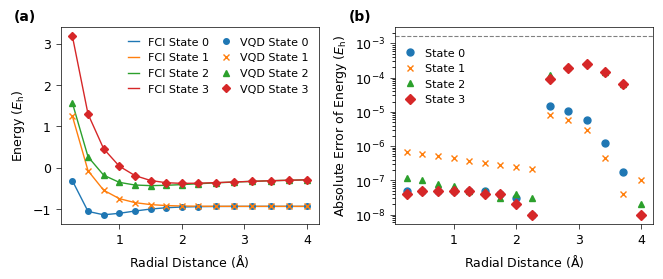

In [4]:

distances_plotting = np.concatenate((np.linspace(0.25, 2.0, 8),
                                     np.linspace(2.25, 4.0, 7)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIGURESIZE)

# --- Panel (a): PES ---
for i in range(4):
    ax1.plot(distances_plotting, fci_values[:, i],
             label=f'FCI State {i}', linestyle='-', color=f'C{i}')
for i in range(4):
    ax1.plot(distances_plotting, vqd_values[:, i],
             label=f'VQD State {i}', marker=markers[i],
             linestyle='', markersize=4, color=f'C{i}')

ax1.set_xlabel(r'Radial Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax1.set_ylabel(r'Energy ($E_\text{h}$)', fontsize=fontsize)
ax1.tick_params(axis='both', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, ncol=2, frameon=False,
           handlelength=1.0, columnspacing=1.0)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Error ---
error = np.abs(vqd_values - fci_values)
colors = [f'C{i}' for i in range(4)]

for i in range(fci_values.shape[1]):
    ax2.plot(distances_plotting, error[:, i], marker=markers[i],
             markersize=5, linestyle='', color=colors[i],
             label=f'State {i}')

ax2.axhline(y=1.6e-3, color='grey', linestyle='--', linewidth=0.8)
ax2.set_yscale('log')
ax2.set_xlabel(r'Radial Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax2.set_ylabel(r'Absolute Error of Energy ($E_\text{h}$)', fontsize=fontsize)
ax2.tick_params(axis='both', labelsize=fontsize)
ax2.legend(fontsize=fontsize - 1, frameon=False, handlelength=1.0, loc='upper left', bbox_to_anchor=(0.0, .945))
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig(f'Plots/H2_PES_and_Error{FILETYPE}', dpi=900, bbox_inches='tight')
plt.show()

# CO2/H2S

## Imports

In [5]:
from third_party.vibrational_dynamics.util_hamil import hamil

In [6]:
from openfermion.linalg import boson_operator_sparse

## Main code

In [7]:
name = 'H2S' # 'H2S' or 'CO2'
trunc = 4

In [8]:
from pathlib import Path

if name == 'H2S':
    p = Path("..") / "data" / "H2S.hdf5"
elif name == 'CO2':
    p = Path("..") / "data" / "CO2.hdf5"

In [10]:
if p.exists():
    H = hamil(name)
    H_original_sparse = boson_operator_sparse(H, trunc=trunc)
    H_original_eigenenergies = np.linalg.eigvalsh(H_original_sparse.todense())
    expected = H_original_eigenenergies
    expected = [float(expect.real) for expect in expected]
else:
    print(f"Vibrational Hamiltonian file not found at  {p}.")

In [11]:
if name == 'H2S':
  H2S_VQD_Energies = [np.float64(3301.734323178507), np.float64(4563.385904767243),
                       np.float64(5807.2645136495), np.float64(5840.035908675143),
                         np.float64(5899.937131541012)] 
  H2S_VQD_Energies = [float(energy) for energy in H2S_VQD_Energies]
  en = H2S_VQD_Energies
elif name == 'CO2':
  en = [
  2535.2439214559486,
  3189.544660844184,
  3189.5446624782257,
  3829.124267040216,
  3847.1697717301276,
  3869.374810850096,
  ] # removed energies that were abnormally high or had high overlap values with previous energies. 

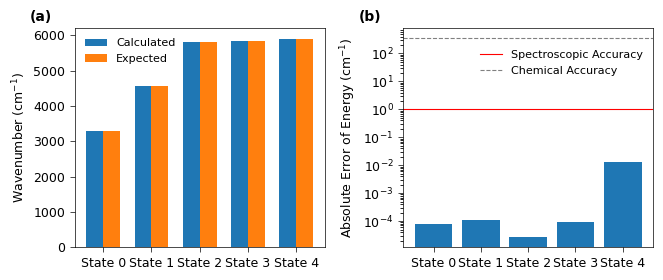

In [12]:
if name == 'H2S':
    max_idx = 5
elif name == 'CO2':
    max_idx = 5

en_subset = en[:max_idx]
expected_subset = expected[:max_idx]
errors = [abs(en_subset[i] - expected_subset[i]) for i in range(max_idx)]

labels = [f'State {i}' for i in range(max_idx)]
x = np.arange(max_idx)
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIGURESIZE)

# --- Panel (a): Energies ---
ax1.bar(x - width/2, en_subset, width, label='Calculated')
ax1.bar(x + width/2, expected_subset, width, label='Expected')

ax1.set_ylabel(r'Wavenumber (cm$^{-1}$)', fontsize=fontsize)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=fontsize)
ax1.tick_params(axis='y', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, frameon=False)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Errors ---
ax2.bar(x, errors)
ax2.set_yscale('log')
ax2.set_ylabel(r'Absolute Error of Energy (cm$^{-1}$)', fontsize=fontsize)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=fontsize)
ax2.tick_params(axis='y', labelsize=fontsize)

ax2.axhline(y=1, color='r', linestyle='-', linewidth=0.8,
            label='Spectroscopic Accuracy')
ax2.axhline(y=350, color='grey', linestyle='--', linewidth=0.8,
            label='Chemical Accuracy')
ax2.legend(fontsize=fontsize - 1, frameon=False, loc='upper right', bbox_to_anchor=(1.0, .945))
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig(f'Plots/{name}_Energies_and_Errors{FILETYPE}', dpi=600, bbox_inches='tight')
plt.show()

# Reduced H4

In [ ]:
from pyscf import gto, scf, fci
import json

## VQD Energies

### Helper Methods

In [14]:
def remove_duplicates(lst, threshold=1e-5):
    unique = []
    for val in lst:
        if not any(abs(val - u) < threshold for u in unique):
            unique.append(val)
    return unique

def get_good_energies(folder_paths, min_overlap=1e-8, remove_duplicates_flag=True, duplicate_threshold=1e-6):
    all_energies = []
    all_overlaps = []
    
    for folder in folder_paths:
        with open(f"{folder}/energies.json") as f:
            all_energies.extend(json.load(f))
        with open(f"{folder}/overlaps.json") as f:
            overlaps_raw = json.load(f)
        all_overlaps.extend([[entry["overlap"] for entry in state] for state in overlaps_raw])
    
    good_indices = [i for i, state in enumerate(all_overlaps) if all(v < min_overlap for v in state)]
    good_energies = [all_energies[i] for i in good_indices]
    if remove_duplicates_flag:
        good_energies = remove_duplicates(good_energies, threshold=duplicate_threshold)
    good_energies.sort()
    return good_energies



def compute_fci_states_h4(R, nroots):
    mol = gto.M(atom=[['H', (i*R,0,0)] for i in range(4)],
                basis='sto-3g')
    mf = scf.RHF(mol).run(verbose=0)
    cis = fci.FCI(mol, mf.mo_coeff)
    e, _ = cis.kernel(nroots=nroots)
    return np.sort(e)

### Gather and Filter Energies from Files

In [16]:
H4_Sliced_Dir = Path.cwd().parent / 'data' / 'Reduced_H4'

In [17]:
en_pt25_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=0.25", ], duplicate_threshold=1e-5)
print("Filtered energies for R=0.25:", en_pt25_vqd_filtered)

en_pt5_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=0.5"], min_overlap=1e-7)
print("Filtered energies for R=0.5:", en_pt5_vqd_filtered)

en_1_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=1.0", ], min_overlap=1e-7, duplicate_threshold=1e-3)
print("Filtered energies for R=1.0:", en_1_vqd_filtered)

en_1pt5_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=1.5",
                                           f"{H4_Sliced_Dir}/R=1.5_V2",
                                           f"{H4_Sliced_Dir}/R=1.5_V3",
                                           f"{H4_Sliced_Dir}/R=1.5_V4"
                                           ], min_overlap=1e-8, duplicate_threshold=1e-3)[:-1]
print("Filtered energies for R=1.5:", en_1pt5_vqd_filtered)

en_2_vqd_filtered = get_good_energies([f"{H4_Sliced_Dir}/R=2.0",
                                        f"{H4_Sliced_Dir}/R=2.0_V2" ,], min_overlap=1e-7, duplicate_threshold=1e-3)
print("Filtered energies for R=2.0:", en_2_vqd_filtered)

vqd_values = [en_pt25_vqd_filtered, en_pt5_vqd_filtered, en_1_vqd_filtered, en_1pt5_vqd_filtered, en_2_vqd_filtered]
distances = [0.25, 0.5, 1.0, 1.5, 2.0]

Filtered energies for R=0.25: [1.5489096818807158, 3.2120538969622254, 3.4937532430518456, 4.362033117909343]
Filtered energies for R=0.5: [-1.6531169529366647, -0.9088625866824616, -0.6228269109803217, -0.336161118468299]
Filtered energies for R=1.0: [-2.1663874576950493, -1.9337570270040718, -1.7194809469135826]
Filtered energies for R=1.5: [-1.996150354718886, -1.9255585304523397, -1.8529031509076062, -1.8217488954102237, -1.7736606370282022]
Filtered energies for R=2.0: [-1.897717069160628, -1.8818777110225247, -1.8648625744657112, -1.856579970356115, -1.8476789439883634, -1.8400105858248224]


## FCI Energies

In [18]:
max_level = max([len(en) for en in vqd_values])

In [19]:
# Dense grid for smooth FCI reference curve

distances_dense = np.linspace(min(distances), max(distances), 50)
fci_values_dense = np.array([compute_fci_states_h4(R, max_level)
                             for R in distances_dense])

In [20]:
colors = [f'C{i}' for i in range(max_level)]

In [21]:
fci_values = np.array([compute_fci_states_h4(R, max_level) for R in distances])

## Plotting

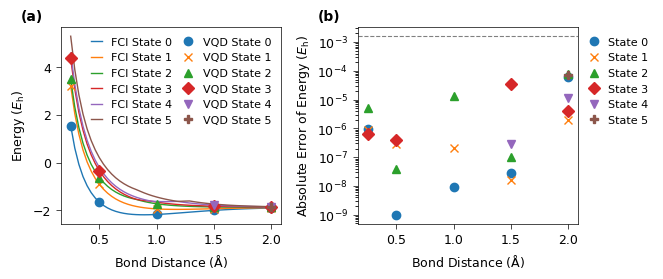

In [22]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIGURESIZE)

# --- Panel (a): PES ---
for i in range(max_level):
    ax1.plot(distances_dense, fci_values_dense[:, i],
             label=f'FCI State {i}', linestyle='-', color=colors[i])

for i in range(max_level):
    xs = [distances[j] for j, en in enumerate(vqd_values) if i < len(en)]
    ys = [en[i]        for en in vqd_values              if i < len(en)]
    ax1.plot(xs, ys, label=f'VQD State {i}', marker=markers[i],
             linestyle='', markersize=markersize, color=colors[i])

ax1.set_xlabel(r'Bond Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax1.set_ylabel(r'Energy ($E_\mathrm{h}$)', fontsize=fontsize)
ax1.tick_params(axis='both', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, ncol=2, frameon=False,
           handlelength=1, columnspacing=1.0)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Error ---
for i in range(max_level):
    xs = [distances[j] for j, en in enumerate(vqd_values) if i < len(en)]
    ys = [abs(en[i] - fci_values[j][i])
          for j, en in enumerate(vqd_values) if i < len(en)]
    ax2.plot(xs, ys, marker=markers[i], linestyle='',
             markersize=markersize, color=colors[i], label=f'State {i}')

ax2.axhline(y=1.6e-3, color='grey', linestyle='--', linewidth=0.8)
ax2.set_yscale('log')
ax2.set_xlabel(r'Bond Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax2.set_ylabel(r'Absolute Error of Energy ($E_\mathrm{h}$)', fontsize=fontsize)
ax2.tick_params(axis='both', labelsize=fontsize)
ax2.legend(fontsize=fontsize - 1, frameon=False, handlelength=1.0,
           loc='upper left', bbox_to_anchor=(1, 1),)
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig(f'Plots/Fig_H4_Sliced_PES_and_Error{FILETYPE}', dpi=600, bbox_inches='tight')
plt.show()